In [ ]:
import pandas as pd
import random as ran
import math
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("./data.csv")

In [3]:
df.head()

,km,price
0,240000,3650
1,139800,3800
2,150500,4400
3,185530,4450
4,176000,5250


In [4]:
df.shape

(24, 2)

In [5]:
print(df)

        km  price
0   240000   3650
1   139800   3800
2   150500   4400
3   185530   4450
4   176000   5250
5   114800   5350
6   166800   5800
7    89000   5990
8   144500   5999
9    84000   6200
10   82029   6390
11   63060   6390
12   74000   6600
13   97500   6800
14   67000   6800
15   76025   6900
16   48235   6900
17   93000   6990
18   60949   7490
19   65674   7555
20   54000   7990
21   68500   7990
22   22899   7990
23   61789   8290


In [6]:
df.size

48

In [7]:
y = df['price']

In [8]:
y

0     3650
1     3800
2     4400
3     4450
4     5250
5     5350
6     5800
7     5990
8     5999
9     6200
10    6390
11    6390
12    6600
13    6800
14    6800
15    6900
16    6900
17    6990
18    7490
19    7555
20    7990
21    7990
22    7990
23    8290
Name: price, dtype: int64

In [9]:
x = df.drop(columns = ["price"])

In [10]:
x

,km
0,240000
1,139800
2,150500
3,185530
4,176000
5,114800
6,166800
7,89000
8,144500
9,84000


In [11]:
si = zip(x, y)
si

In [12]:
print(x[:5])
print(y[:5])

print(type(x))
print(type(y))

       km
0  240000
1  139800
2  150500
3  185530
4  176000
0    3650
1    3800
2    4400
3    4450
4    5250
Name: price, dtype: int64
<class 'pandas.DataFrame'>
<class 'pandas.Series'>


In [13]:
data = list(zip(x['km'], y))
ran.seed(42)
ran.shuffle(data)
print(data)

[(76025, 6900), (114800, 5350), (60949, 7490), (61789, 8290), (97500, 6800), (82029, 6390), (93000, 6990), (63060, 6390), (67000, 6800), (48235, 6900), (139800, 3800), (74000, 6600), (68500, 7990), (166800, 5800), (84000, 6200), (150500, 4400), (22899, 7990), (176000, 5250), (65674, 7555), (89000, 5990), (144500, 5999), (240000, 3650), (185530, 4450), (54000, 7990)]


In [14]:
index = int( len(data) * 0.8)
x_train = data[: index]
y_test = data[index :]
print(x_train)
print(y_test)

[(76025, 6900), (114800, 5350), (60949, 7490), (61789, 8290), (97500, 6800), (82029, 6390), (93000, 6990), (63060, 6390), (67000, 6800), (48235, 6900), (139800, 3800), (74000, 6600), (68500, 7990), (166800, 5800), (84000, 6200), (150500, 4400), (22899, 7990), (176000, 5250), (65674, 7555)]
[(89000, 5990), (144500, 5999), (240000, 3650), (185530, 4450), (54000, 7990)]


VERIFICAR A ESCALA DOS VALORES

In [15]:
df[['km', 'price']].describe()

,km,price
count,24.000000,24.000000
mean,101066.250000,6331.833333
std,52674.245606,1319.654193
min,22899.000000,3650.000000
25%,65020.500000,5687.500000
50%,83014.500000,6495.000000
75%,140975.000000,7115.000000
max,240000.000000,8290.000000


In [16]:
df_sort_km = df.sort_values('km')
df_sort_price = df.sort_values('price', ascending = False)

In [17]:
df_sort_km.head()

,km,price
22,22899,7990
16,48235,6900
20,54000,7990
18,60949,7490
23,61789,8290


In [18]:
df_sort_price.head()

,km,price
23,61789,8290
20,54000,7990
21,68500,7990
22,22899,7990
19,65674,7555


In [19]:
par = []
par1 = []

x_tra = [par[0] for par in x_train]
y_tra = [par[1] for par in x_train]


In [20]:
par1 = []

x_tes = [par1[0] for par1 in y_test]
y_tes = [par1[1] for par1 in y_test]


In [21]:

media_train_y = sum(y_tra) / len(y_tra)
media_train_x = sum(x_tra) / len(x_tra)

# CALCULAR O DESVIO PADRÃO 
desvio_train_x = math.sqrt(
    sum((km - media_train_x) ** 2 for km in x_tra) / len(x_tra)
)


# NORMALIZAMOS EM UMA CALA DE KM COM DESVIO PADRÃO DOS DADOS DE TESTE
x_test_transf = [
    (km - media_train_x) / desvio_train_x for km in x_tes
]

# NORMALIZAMOS EM UMA CALA DE KM COM DESVIO PADRÃO DOS DADOS DE TREINO
x_train_transf = [
    (km - media_train_x) / desvio_train_x for km in x_tra
]

print("Média de X:", media_train_x)
print("Desvio-padrão de X:", desvio_train_x)

print("Média de X transformado:",
      sum(x_train_transf) / len(x_train_transf))

print("Primeiros valores transformados:", x_train_transf[:5])

desvio_x_transf = math.sqrt(
    sum((z - sum(x_train_transf) / len(x_train_transf)) ** 2
        for z in x_train_transf) / len(x_train_transf)
)

print("Desvio-padrão transformado:", desvio_x_transf)

Média de X: 90134.73684210527
Desvio-padrão de X: 40301.99222167573
Média de X transformado: -1.1321353211638108e-16
Primeiros valores transformados: [-0.3501002323780061, 0.6120110147961605, -0.7241760328266904, -0.7033333907215634, 0.18275183810723514]
Desvio-padrão transformado: 0.9999999999999999


In [22]:
b0 = media_train_y; b1 = 0.0

In [23]:
print(x_tra[:5])
print(y_tra[:5])
print("-----------------------------------------")
print(x_train_transf[:5])

[76025, 114800, 60949, 61789, 97500]
[6900, 5350, 7490, 8290, 6800]
-----------------------------------------
[-0.3501002323780061, 0.6120110147961605, -0.7241760328266904, -0.7033333907215634, 0.18275183810723514]


CALCULAR A PRIMEIRA PREVISÃO

In [24]:
y_prev = []

for x in x_train_transf:
    prevision = b0 + b1 * x
    y_prev.append(prevision)
print(y_prev)

[6520.263157894737, 6520.263157894737, 6520.263157894737, 6520.263157894737, 6520.263157894737, 6520.263157894737, 6520.263157894737, 6520.263157894737, 6520.263157894737, 6520.263157894737, 6520.263157894737, 6520.263157894737, 6520.263157894737, 6520.263157894737, 6520.263157894737, 6520.263157894737, 6520.263157894737, 6520.263157894737, 6520.263157894737]


TREINAR O MODELO POR MUITAS ITERAÇÕES

In [25]:
m = len(x_tra)
epoch = 500
for epoch in range(epoch):
    db0 = 0
    db1 = 0
    sqr = 0
    
    # VAMOS CALCULAR O GRADIENTE
    for i in range(m):
        prevision = b0 + b1 * x_train_transf[i]
        error = prevision - y_tra[i]
        db0 += error
        db1 += error * x_train_transf[i]
    db0 /= m
    db1 /= m
    
    # VAMOS ACTUALIZAR OS PESOS - aqui acontece adecisão se aumentamos ou diminuimos
    alpha = 0.1
    
    novo_b0 = b0 - alpha * db0
    novo_b1 = b1 - alpha * db1
        
    # ACTUALIZAR OS PARÂMETROS DO MODELO
    b0 = novo_b0
    b1 = novo_b1
    
    # MSE (QUADRADO DAS MEDIA DOS ERROS)
    for i in range(m):
        prevision = b0 + b1 * x_train_transf[i]
        error = prevision - y_tra[i]
        sqr += error * error
    mse = sqr / m 

    if epoch %100 == 0:
       print('Epoch = ',epoch, 'MSE = ', mse)
       print('db0 = ', db0, 'db1 = ', db1)
       print('b0 = ', b0, 'b1 = ', b1)

Epoch =  0 MSE =  1187780.3853911438
db0 =  -1.9147256879430067e-13 db1 =  926.8384234032484
b0 =  6520.263157894737 b1 =  -92.68384234032484
Epoch =  100 MSE =  491966.5207737841
db0 =  -9.573628439715034e-14 db1 =  0.024618125068418283
b0 =  6520.263157894737 b1 =  -926.8162670906871
Epoch =  200 MSE =  491966.52028288174
db0 =  -9.573628439715034e-14 db1 =  6.538917378556538e-07
b0 =  6520.263157894737 b1 =  -926.838422814746
Epoch =  300 MSE =  491966.5202828818
db0 =  -4.786814219857517e-14 db1 =  1.7376135618082786e-11
b0 =  6520.263157894737 b1 =  -926.838423403233
Epoch =  400 MSE =  491966.5202828819
db0 =  -1.9147256879430067e-13 db1 =  4.338050386745875e-13
b0 =  6520.263157894737 b1 =  -926.8384234032482


In [31]:
sqr1 = 0
for i in range(m):
    prev = b0 + b1 * x_train_transf[i]
    error = prev - y_tra[i]
    sqr1 += error * error
    print("prevision = ", prev, "price", y_tra[i])
mse1 = sqr1 / m
print("mse1 = ", mse1)

prevision =  6844.749505305079 price 6900
prevision =  5953.027833835641 price 5350
prevision =  7191.457330426245 price 7490
prevision =  7172.139568877971 price 8290
prevision =  6350.881732389381 price 6800
prevision =  6706.673504905272 price 6390
prevision =  6454.369740683706 price 6990
prevision =  7142.909955868618 price 6390
prevision =  7052.300455273143 price 6800
prevision =  7483.84544986048 price 6900
prevision =  5378.094454422722 price 3800
prevision =  6891.319109037525 price 6600
prevision =  7017.804452508367 price 7990
prevision =  4757.166404656769 price 5800
prevision =  6661.345757272357 price 6200
prevision =  5132.022968033993 price 4400
prevision =  8066.505933892708 price 7990
prevision =  4545.5909210328155 price 5250
prevision =  7082.794921717204 price 7555
mse1 =  491966.5202828819


In [33]:
sqr2 = 0
for i in range(len(x_tes)):
    prev = b0 + b1 * x_test_transf[i]
    error = prev - y_tes[i]
    sqr2 += error * error
    print("prevision test = ", prev, "price test =", y_tes[i])
mse2 = sqr2 / len(x_tes)
print("mse2 = ", mse2)

prevision test =  6546.359081389774 price test = 5990
prevision test =  5270.006979093094 price test = 5999
prevision test =  3073.761469735743 price test = 3650
prevision test =  4326.426316800611 price test = 4450
prevision test =  7351.26581256786 price test = 7990
mse2 =  319253.782622204


GRAFICO PARA ENTENDER MELHOR OS DADOS

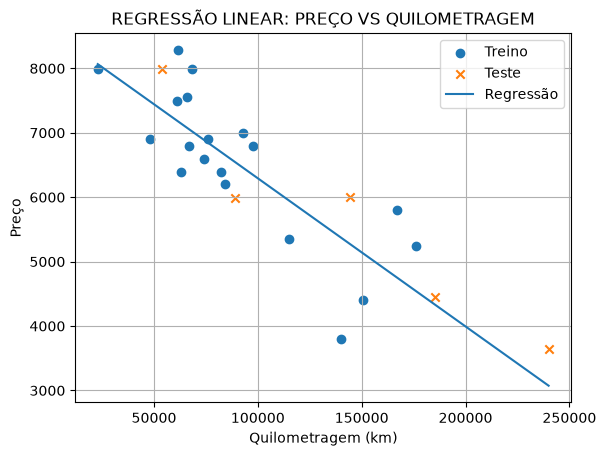

In [50]:
 #previsões para desenhar a linha
x_line = sorted(x_tra + x_tes)

y_line = [
    b0 + b1 * ((km - media_train_x) / desvio_train_x) for km in x_line
]

#dados de treino
plt.scatter(x_tra, y_tra, label = 'Treino')
#dados de teste
plt.scatter(x_tes, y_tes, label = 'Teste', marker = 'x')
#Linha aprendida
plt.plot(x_line, y_line, label = 'Regressão')

plt.xlabel('Quilometragem (km)')
plt.ylabel('Preço')
plt.title('REGRESSÃO LINEAR: PREÇO VS QUILOMETRAGEM')
plt.legend()
plt.grid()
plt.show()